  ***Integrantes:** Jhoan Avila Gutierrez*<br>
  ***Clase:** Procesamiento Lenguaje Natural*<br>
  ***Programa:** Esp. Inteligencia Artificial, Universidad de Cundinamarca*

# 🚀 Clasificación de Desempeño de Videos de YouTube basado en Comentarios (Modelo NLP & MLOps)

En este notebook se elaboro el trabajo para entrenar un modelo de Procesamiento de Lenguaje Natural (NLP) que predice si un video tendrá un alto o bajo desempeño basándose en el análisis de texto de sus comentarios.

## 📦 0. Instalación y Configuración del Entorno

Ejecutar la siguiente celda para instalar y descargar los paquetes necesarios en el ambiente local para permitir la manipulacion de datos, manejo de errores o excepciones, creación del pipeline, entrenamiento de modelos y visualizacion de datos.

In [1]:
import os
import re
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
)
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore", category=FutureWarning)
print("✅ Entorno inicial de NLP configurado exitosamente.")

✅ Entorno inicial de NLP configurado exitosamente.


## ⚙️ 1. Descarga y carga del Dataset desde Kaggle
Este notebook requiere del dataset `youtube-statistics` de Kaggle. Este dataset se encuentra en el mismo github de este archivo y contiene la estructura de los comentarios asociados a las estadisticas un video de YouTube.

**Agrega los archivos** `comments.csv` y `videos-stats.csv` en la misma ubicación de este notebook. **Si se ejecuta en Google Colab, agregar archivos en** `/content`.

In [5]:
print("📥 Descargando YouTube Statistics de Kaggle a Colab...")
print("Cargando archivos del dataset de YouTube... \n")

# Buscamos si el archivo de comentarios extraído de youtube-statistics existe
COMMENTS_FILE = 'comments.csv'
VIDEOS_FILE = 'videos-stats.csv'

if os.path.exists(COMMENTS_FILE) and os.path.exists(VIDEOS_FILE):

  df_comments = pd.read_csv(COMMENTS_FILE,encoding="utf-8-sig",on_bad_lines="warn")
  df_videos = pd.read_csv(VIDEOS_FILE,encoding="utf-8-sig",on_bad_lines="warn")

  # Normalizar espacios de los encabezados.
  df_comments.columns = df_comments.columns.str.strip()
  df_videos.columns = df_videos.columns.str.strip()

  print(
      f'✅ Comentarios cargados: {len(df_comments)} | Videos cargados:'
      f' {len(df_videos)}'
  )
else:
  # Simulación de datos para el modelo
  print('⚠️ Hace falta el archivo comments.csv o videos-stats.csv. ¡VALIDE POR FAVOR!')


📥 Descargando YouTube Statistics de Kaggle a Colab...
Cargando archivos del dataset de YouTube... 

✅ Comentarios cargados: 18409 | Videos cargados: 1881


## 🛠️ 2. Preprocesamiento de NLP
Limpieza de datos apicando normalización de texto, stopwords, elimiando valores duplicados o vacios y parseando los tipos de textos.

In [6]:
# Limpieza de datos
df_comments = df_comments.dropna(subset=["Video ID", "Comment"]).copy()
df_videos = df_videos.dropna(subset=["Video ID", "Views"]).copy()

# Normalizar identificadores.
df_comments["Video ID"] = (df_comments["Video ID"].astype(str).str.strip())
df_videos["Video ID"] = (df_videos["Video ID"].astype(str).str.strip())

# Convertir vistas a valores numéricos.
df_videos["Views"] = pd.to_numeric(df_videos["Views"], errors="coerce")

df_videos = df_videos.dropna(subset=["Views"])
df_videos = df_videos[df_videos["Views"] >= 0]

# Eliminar IDs vacíos.
df_comments = df_comments[df_comments["Video ID"].ne("")].copy()
df_videos = df_videos[df_videos["Video ID"].ne("")].copy()

# Si hay varias filas por video usamos la última fila solo si existe una fecha de actualización verificable.
# Sin fecha, se detiene para evitar elegir aletoriamente.
for col in ["Views", "Likes", "Comments"]:
    df_videos[col] = pd.to_numeric(
        df_videos[col], errors="coerce"
    )

# Eliminar filas sin identificador ni visualizaciones válidas.
df_videos = df_videos.dropna(subset=["Video ID", "Views"]).copy()
df_videos["Video ID"] = (df_videos["Video ID"].astype(str).str.strip())

# Comprobar cuántos IDs aparecen más de una vez.
duplicados = df_videos["Video ID"].duplicated().sum()
print("   Registros duplicados por Video ID:", duplicados)

if duplicados > 0:
    # Verificar que cada ID tenga un título y fecha de publicación, cuando estén disponibles.
    for col in ["Title", "Published At"]:
        if col in df_videos.columns:
            inconsistentes = (
                df_videos.groupby("Video ID")[col]
                .nunique(dropna=True)
            )
            inconsistentes = inconsistentes[inconsistentes > 1 ]

            if not inconsistentes.empty:
                raise ValueError(
                    f"Hay videos con valores inconsistentes "
                    f"en '{col}'. Revisa esos IDs antes "
                    "de consolidar."
                )

    # Las vistas son acumuladas: usar el máximo observado.
    # Para Likes y Comments también se usa el máximo como aproximación a la mayor cifra registrada.
    df_videos = (
        df_videos.groupby("Video ID", as_index=False)
        .agg({ "Title": "first", "Published At": "first", "Keyword": "first", "Likes": "max", "Comments": "max", "Views": "max"})
    )

print("✅ Videos únicos después de consolidar:", df_videos["Video ID"].nunique())
print("   Duplicados restantes:", df_videos["Video ID"].duplicated().sum())

# Eliminar comentarios duplicados exactos.
df_comments["Comment"] = (df_comments["Comment"].astype(str).str.strip())
antes = len(df_comments)
df_comments = df_comments.drop_duplicates( subset=["Video ID", "Comment"] ).copy()
print('⛔ Comentarios duplicados eliminados:', antes - len(df_comments))


# LIMPIEZA DE TEXTO EN INGLÉS
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    return " ".join(text.split())

df_comments["clean_comment"] = (df_comments["Comment"].map(clean_text))
df_comments = df_comments[df_comments["clean_comment"].str.len() > 0].copy()

   Registros duplicados por Video ID: 12
✅ Videos únicos después de consolidar: 1867
   Duplicados restantes: 0
⛔ Comentarios duplicados eliminados: 249


## 3. 🏷️ Agrupación y consolidado de datos NLP
Agrupación de comentarios con video correspondiente por ID. Se descartan videos sin comentarios o comentarios sin relacion a algun video.

Posteriormente, consolidados los datos a procesar se define que videos tienen un **alto desempeño** `performance_class = 1` o **bajo desempeño** `performance_class = 0` calculando la **mediana de visualizaciones** del dataset de videos.

In [7]:
# AGRUPAR COMENTARIOS POR VIDEO
print('🔄 Agrupando comentarios por Video ID... \n')
comments_grouped = (
    df_comments.groupby("Video ID")["clean_comment"]
    .agg(" ".join)
    .rename("text")
    .reset_index()
)

# Una sola fila de estadísticas por video.
df_final = comments_grouped.merge(
    df_videos[["Video ID", "Views"]],
    on="Video ID",
    how="inner",
    validate="one_to_one",
)

# Descartar textos vacíos y videos sin comentarios útiles.
df_final = df_final[df_final["text"].str.strip().ne("")].copy()

if len(df_final) < 20:
    raise ValueError(
        f"Solo hay {len(df_final)} videos con comentarios y vistas. "
        "Se necesitan más ejemplos para una evaluación razonable."
    )

# DEFINICIÓN DEL TARGET: Desempeño del Video basado en la Mediana de Vistas
umbral_vistas = df_final["Views"].median()
df_final["performance_class"] = (df_final["Views"] >= umbral_vistas).astype(int)


print(f'✅ Videos consolidados para entrenar: {len(df_final)}')
print(f'📊 Umbral de corte (Mediana de vistas): {umbral_vistas:,.0f} visualizaciones \n')
print(f"Videos de Alto Desempeño: {int((df_final["performance_class"] == 1).sum())}")
print(f"Videos de Bajo Desempeño: {int((df_final["performance_class"] == 0).sum())} \n")

print('\n' + '=' * 60)
print('📊 PREVISUALIZACIÓN DE DATOS POR VIDEO')
print('=' * 60)
display(df_final.head())

🔄 Agrupando comentarios por Video ID... 

✅ Videos consolidados para entrenar: 1867
📊 Umbral de corte (Mediana de vistas): 591,721 visualizaciones 

Videos de Alto Desempeño: 934
Videos de Bajo Desempeño: 933 


📊 PREVISUALIZACIÓN DE DATOS POR VIDEO


,Video ID,text,Views,performance_class
0,--ZI0dSbbNU,he s so happy while eating because he can see ...,17975269.0,1
1,--hxd1CrOqg,it s really unfortunate that the intended targ...,808787.0,1
2,--ixiTypG8g,the biggest problem is colleges charging outra...,97434.0,0
3,-64r1hcxtV4,8 20 10 00 what are your thoughts about what h...,5283664.0,1
4,-6IgkG5yZfo,hope this will make your life easier 00 47 uni...,844015.0,1


## 🔍 4. Selección de modelo mas optimo
Con una **validación cruzada** `Stratified K-Fold` evaluamos los modelos `Random Forest` y `Regresión Logística` para medir cual se generaliza mejor con los datos.

Para esta validación creamos un división `K=5` menteniendo la misma proporción en el conjunto de datos original. Al finalizar, **se calcula el promedio de las métricas obtenidas para evaluar que modelo es el mas confiable**.

In [9]:
# SEPARAR ENTRENAMIENTO Y PRUEBA
X = df_final["text"]
y = df_final["performance_class"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("\nVideos de entrenamiento:", len(X_train))
print("Videos de prueba:", len(X_test))

# DEFINIR PIPELINES

def make_pipeline(classifier):
    return Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                stop_words="english",
                max_features=10000,
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                sublinear_tf=True,
                dtype=np.float32,
            ),
        ),
        ("classifier", classifier),
    ])


models = {
    "Random Forest": make_pipeline(
        RandomForestClassifier(
            n_estimators=300,
            max_depth=30,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
        )
    ),

    "Regresión Logística": make_pipeline(
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            max_iter=2000,
            random_state=42,
        )
    ),
}

# VALIDACIÓN CRUZADA EN EL ENTRENAMIENTO

# Nunca usamos el test para escoger el modelo.
# Ajustamos TF-IDF dentro de cada fold mediante Pipeline.
min_class_count = int(y_train.value_counts().min())
n_splits = min(5, min_class_count)

cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

scoring = {
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc",
}
cv_results = {}
trained_models = {}

print("\n" + "=" * 60)
print("📈 Stratified K-Fold")
print("=" * 60)

for name, pipeline in models.items():

    print(f"\n 🔍Evaluando modelo: {name}")

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
    )

    cv_results[name] = scores

    print(
        f"F1: {scores['test_f1'].mean():.3f} "
        f"+/- {scores['test_f1'].std():.3f}"
    )
    print(
        "Balanced accuracy: "
        f"{scores['test_balanced_accuracy'].mean():.3f} "
        f"+/- {scores['test_balanced_accuracy'].std():.3f}"
    )
    print(
        f"ROC-AUC: {scores['test_roc_auc'].mean():.3f} "
        f"+/- {scores['test_roc_auc'].std():.3f}"
    )


Videos de entrenamiento: 1493
Videos de prueba: 374

📈 Stratified K-Fold

 🔍Evaluando modelo: Random Forest
F1: 0.732 +/- 0.018
Balanced accuracy: 0.713 +/- 0.020
ROC-AUC: 0.777 +/- 0.026

 🔍Evaluando modelo: Regresión Logística
F1: 0.737 +/- 0.027
Balanced accuracy: 0.723 +/- 0.024
ROC-AUC: 0.799 +/- 0.020


## 💪 5. Entrenamiento de Modelo NLP
El modelo con mejores metricas F1-Score se entrena con el conjunto de datos de entrenamiento y prueba para clasificar el desempeño de videos Youtube basado en sus comentarios.


 🏆 MODELO ENTRENADO: Regresión Logística

📊 REPORTE DE CLASIFICACIÓN DE DESEMPEÑO DEL VIDEO
                precision    recall  f1-score   support

Bajo desempeño       0.75      0.67      0.71       187
Alto desempeño       0.70      0.78      0.74       187

      accuracy                           0.72       374
     macro avg       0.73      0.72      0.72       374
  weighted avg       0.73      0.72      0.72       374



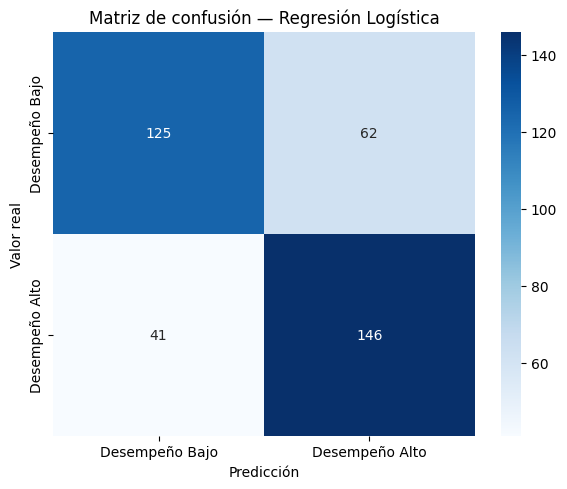

In [27]:
# SELECCIONAR EL MODELO
best_name = max(cv_results, key=lambda name: cv_results[name]["test_f1"].mean() )
best_model = clone(models[best_name])
print("\n 🏆 MODELO ENTRENADO:", best_name)

# Entrenar con todos los datos de entrenamiento.
best_model.fit(X_train, y_train)


# EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]


print('\n' + '=' * 60)
print('📊 REPORTE DE CLASIFICACIÓN DE DESEMPEÑO DEL VIDEO')
print('=' * 60)
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Bajo desempeño", "Alto desempeño"],
        zero_division=0,
    )
)

# VISUALIZAR LA MATRIZ DE CONFUSIÓN
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Desempeño Bajo", "Desempeño Alto"],
    yticklabels=["Desempeño Bajo", "Desempeño Alto"],
    ax=ax,
)
ax.set_title(f"Matriz de confusión — {best_name}")
ax.set_xlabel("Predicción")
ax.set_ylabel("Valor real")

plt.tight_layout()
plt.show()

## 📈 6. Evaluación y comparación de modelos
Como los modelo no aprende directamente a contar visualizaciones. Este evaluación de metricas busca conocer cual aprende a relacionar mejor los patrones de palabras de los comentarios con la categoría de desempeño de cada video.

In [28]:
# EVALUACIÓN DE MODELO
ROC = 0
if y_test.nunique() == 2:
    ROC = roc_auc_score(y_test, y_prob);

# Metricas
datametricas = {
    "Métricas de modelo elegido": [
        "Accuracy", "Balanced Accuracy","Precision (Clase Alta)", "Recall (Clase Alta)", "F1-Score (Clase Alta)", "ROC-AUC"
    ],
    "Valor": [
        round(accuracy_score(y_test, y_pred), 3),
        round(balanced_accuracy_score(y_test, y_pred), 3),
        round(precision_score(y_test, y_pred, zero_division=0), 3),
        round(recall_score(y_test, y_pred, zero_division=0), 3),
        round(f1_score(y_test, y_pred, zero_division=0), 3),
        round(ROC, 3),
    ]
}
print('\n' + '=' * 60)
print('📊 METRICAS DE MODELO ENTRENADO:', best_name)
print('=' * 60)
dfmetricas = pd.DataFrame(datametricas)
display( dfmetricas )


# COMPARACIÓN DE LOS MODELOS
comparison = pd.DataFrame([
    {
        "Modelo": name,
        "F1 medio CV": result["test_f1"].mean(),
        "Desviación F1": result["test_f1"].std(),
        "Balanced accuracy CV":
            result["test_balanced_accuracy"].mean(),
        "ROC-AUC CV": result["test_roc_auc"].mean(),
    }
    for name, result in cv_results.items()
]).sort_values("F1 medio CV", ascending=False)

print('\n' + '=' * 60)
print('📊 REPORTE COMPARACIÓN DE MODELOS')
print('=' * 60)
print(comparison.round(3).to_string(index=False))


📊 METRICAS DE MODELO ENTRENADO: Regresión Logística


,Métricas de modelo elegido,Valor
0,Accuracy,0.725
1,Balanced Accuracy,0.725
2,Precision (Clase Alta),0.702
3,Recall (Clase Alta),0.781
4,F1-Score (Clase Alta),0.739
5,ROC-AUC,0.792



📊 REPORTE COMPARACIÓN DE MODELOS
             Modelo  F1 medio CV  Desviación F1  Balanced accuracy CV  ROC-AUC CV
Regresión Logística        0.737          0.027                 0.723       0.799
      Random Forest        0.732          0.018                 0.713       0.777


## 👀 7. Predicción de videos a partir de sus comentarios
Ejecute este bloque para cargar la funcion `predecir_desempeno_video()` y en el siguiente bloque agregue los comentarios del video que sea evaluar *(desempeño alto o bajo)*.

In [29]:
# Predecir el Desempeño de un video a partir de sus comentarios

def predecir_desempeno_video(lista_comentarios):

    comentarios = [
        clean_text(c)
        for c in lista_comentarios
        if isinstance(c, str) and c.strip()
    ]

    if not comentarios:
        raise ValueError("No hay comentarios válidos para analizar.")

    texto_video = " ".join(comentarios)
    pred = int(best_model.predict([texto_video])[0])
    probabilidades = best_model.predict_proba([texto_video])[0]

    clases = list(best_model.classes_)
    prob_alto = float(probabilidades[clases.index(1)])
    prob_predicha = float(probabilidades[clases.index(pred)])

    # Regla descriptiva, no una calibración estadística.
    if prob_predicha < 0.60: interpretacion = "Predicción poco concluyente"
    elif prob_predicha < 0.75: interpretacion = "Predicción de confianza moderada"
    else: interpretacion = "Probabilidad estimada relativamente alta"

    return {
        "Predicción": (
            "🔥 ALTO DESEMPEÑO"
            if pred == 1
            else "⚪BAJO DESEMPEÑO"
        ),
        "Comentarios analizados": len(comentarios),
        "Modelo": best_name,
        "Desempeño de video":
            f"{prob_alto:.1%}",
        "% Prediccion":
            f"{prob_predicha:.1%}",
        "Interpretación": interpretacion,
        "Umbral de vistas en entrenamiento":
            float(umbral_vistas),
    }

📝 Ingrese los comentarios para **predecir si el video tiene un alto o bajo desempeño**:

In [30]:

# Pruebas en vivo con comentarios simulados de un video
video_ejemplo_1 = [
    'This is the best documentary on the subject, incredible cinematography.',
    'I learned more in 15 minutes than in an entire semester, thank you!',
    'Rewatching this for the third time, pure quality.',
    'Subscribed, shared with all my colleagues.',
    'This video is amazing! I learned so much',
    'Great explanation, very clear and concise.',
]

video_ejemplo_2 = [
    'Total clickbait, the title has nothing to do with the video.',
    'Terrible audio mix, cannot understand anything.',
    'Boring presentation, disliked.',
    'Complete waste of time, do not watch.',
]

print('\n=== PRUEBA EN VIDEO 1 ===')
print(predecir_desempeno_video(video_ejemplo_1))

print('\n=== PRUEBA EN VIDEO 2 ===')
print(predecir_desempeno_video(video_ejemplo_2))


=== PRUEBA EN VIDEO 1 ===
{'Predicción': '🔥 ALTO DESEMPEÑO', 'Comentarios analizados': 6, 'Modelo': 'Regresión Logística', 'Desempeño de video': '61.0%', '% Prediccion': '61.0%', 'Interpretación': 'Predicción de confianza moderada', 'Umbral de vistas en entrenamiento': 591721.0}

=== PRUEBA EN VIDEO 2 ===
{'Predicción': '⚪BAJO DESEMPEÑO', 'Comentarios analizados': 4, 'Modelo': 'Regresión Logística', 'Desempeño de video': '42.2%', '% Prediccion': '57.8%', 'Interpretación': 'Predicción poco concluyente', 'Umbral de vistas en entrenamiento': 591721.0}
